
# Práctica 1. Agente lógico del Wumpus

**Asignatura:** Inteligencia Artificial (CDC-2411)

**Unidad 3:** Representación del conocimiento y razonamiento

**Subtemas:**
- 3.1 Lógica de proposiciones.
- 3.2 Agentes lógicos.

**Modalidad:** Individual.

## 1. Objetivo

Representar mediante lógica proposicional el conocimiento de un agente inteligente e implementar un algoritmo de comprobación de modelos que permita determinar qué casillas están libres de pozos y cuáles presentan incertidumbre.



## 2. Fundamento teórico

### 2.1. Mundo del Wumpus

El mundo del Wumpus representa un entorno en el que un agente inteligente debe desplazarse por una cueva que contiene peligros.

En esta práctica analizaremos la presencia de pozos mediante las percepciones de brisa del agente.

El agente comienza en la casilla [1,1], donde no percibe brisa. Posteriormente, se desplaza a la casilla [2,1], donde sí percibe brisa.

### 2.2. Símbolos proposicionales

| Símbolo | Significado |
|---|---|
| $P_{11}$ | Hay un pozo en [1,1]. |
| $P_{12}$ | Hay un pozo en [1,2]. |
| $P_{21}$ | Hay un pozo en [2,1]. |
| $P_{22}$ | Hay un pozo en [2,2]. |
| $P_{31}$ | Hay un pozo en [3,1]. |
| $B_{11}$ | Hay brisa en [1,1]. |
| $B_{21}$ | Hay brisa en [2,1]. |

### 2.3. Base de conocimiento (KB)

La base de conocimiento está formada por las siguientes reglas:

| Regla | Fórmula | Significado |
|---|---|---|
| R1 | $\neg P_{11}$ | No hay pozo en la casilla inicial. |
| R2 | $B_{11}\Leftrightarrow(P_{12}\lor P_{21})$ | Hay brisa en [1,1] si y solo si hay un pozo vecino. |
| R3 | $B_{21}\Leftrightarrow(P_{11}\lor P_{22}\lor P_{31})$ | Hay brisa en [2,1] si y solo si hay un pozo vecino. |
| R4 | $\neg B_{11}$ | No hay brisa en [1,1]. |
| R5 | $B_{21}$ | Hay brisa en [2,1]. |

### 2.4. Comprobación de modelos

Un modelo es una asignación de valores de verdad a los símbolos proposicionales.

Para n símbolos existen $2^n$ modelos posibles.

Una proposición es consecuencia lógica de la base de conocimiento si es verdadera en todos los modelos que satisfacen dicha base:

$$KB \models \alpha$$



## 3. Preguntas previas

### 1. ¿Cuántos modelos hay con los siete símbolos proposicionales?

Cada símbolo puede tomar dos valores: verdadero o falso.

Por lo tanto:

$$2^7 = 128$$

Existen 128 modelos posibles.

### 2. ¿Por qué R2 se escribe con un bicondicional y no con una implicación? ¿Qué conclusión se perdería?

El bicondicional permite establecer una relación lógica en ambas direcciones entre la presencia de brisa y la existencia de pozos vecinos.

Si únicamente se utilizara la implicación:

$$B_{11}\Rightarrow(P_{12}\lor P_{21})$$

no sería posible deducir que las casillas vecinas están libres de pozos cuando el agente no percibe brisa.

### 3. Razonando a mano, ¿qué casillas puedes asegurar que no tienen pozo?

Las casillas [1,1], [1,2] y [2,1].

La primera se determina mediante R1. Las otras dos se deducen mediante R2 y R4, ya que la ausencia de brisa en [1,1] implica que no existen pozos en sus casillas vecinas.



## 4. Desarrollo de la práctica

### 4.1. Importación de bibliotecas y definición de símbolos

Se utilizará la biblioteca itertools para generar todas las combinaciones posibles de valores de verdad de los símbolos proposicionales.


In [1]:

# Importar biblioteca para generar combinaciones
import itertools

# Definir los símbolos proposicionales
SIMB = ["P11", "P12", "P21", "P22", "P31", "B11", "B21"]

# Calcular el número de modelos posibles
n = len(SIMB)
total_modelos = 2 ** n

# Mostrar resultados
print("Símbolos proposicionales:", SIMB)
print("Cantidad de símbolos:", n)
print("Total de modelos posibles:", total_modelos)


Símbolos proposicionales: ['P11', 'P12', 'P21', 'P22', 'P31', 'B11', 'B21']
Cantidad de símbolos: 7
Total de modelos posibles: 128



### 4.2. Implementación del bicondicional lógico

El bicondicional es verdadero cuando ambas proposiciones tienen el mismo valor de verdad y falso cuando sus valores son diferentes.

$$a\Leftrightarrow b$$

Se implementará mediante el operador de igualdad de Python.


In [2]:

def iff(a, b):
    """Devuelve True cuando a y b tienen el mismo valor."""
    return a == b


# Comprobar el funcionamiento del bicondicional
print("TABLA DE VERDAD DEL BICONDICIONAL")
print("-" * 35)
print(f"{'a':<10}{'b':<10}{'a ⇔ b'}")
print("-" * 35)

for a, b in itertools.product([False, True], repeat=2):
    print(f"{str(a):<10}{str(b):<10}{iff(a, b)}")


TABLA DE VERDAD DEL BICONDICIONAL
-----------------------------------
a         b         a ⇔ b
-----------------------------------
False     False     True
False     True      False
True      False     False
True      True      True



### 4.3. Formalización de la base de conocimiento (KB)

La función `KB(m)` recibe un modelo representado mediante un diccionario y verifica si satisface las cinco reglas proposicionales.

Para que un modelo sea válido, todas las reglas deben cumplirse simultáneamente:

$$KB = R_1 \land R_2 \land R_3 \land R_4 \land R_5$$

Se utilizarán los operadores lógicos de Python:

- `not`: negación.
- `and`: conjunción.
- `or`: disyunción.
- `iff()`: bicondicional.


In [3]:

def KB(m):
    """Devuelve True si el modelo satisface las reglas R1 a R5."""

    # R1: No hay pozo en [1,1].
    r1 = not m["P11"]

    # R2: Brisa en [1,1] si y solo si hay un pozo vecino.
    r2 = iff(m["B11"], m["P12"] or m["P21"])

    # R3: Brisa en [2,1] si y solo si hay un pozo vecino.
    r3 = iff(m["B21"], m["P11"] or m["P22"] or m["P31"])

    # R4: No hay brisa en [1,1].
    r4 = not m["B11"]

    # R5: Hay brisa en [2,1].
    r5 = m["B21"]

    # Todas las reglas deben cumplirse.
    return r1 and r2 and r3 and r4 and r5



#### 4.3.1. Comprobación de la base de conocimiento

Se evaluarán dos modelos de prueba:

- Un modelo que satisface todas las reglas.
- Un modelo que contradice la regla R1, al presentar un pozo en la casilla inicial.

Esto permite verificar el funcionamiento de la función `KB()` antes de continuar.


In [4]:

# Modelo que satisface las cinco reglas
modelo_valido = {
    "P11": False,
    "P12": False,
    "P21": False,
    "P22": True,
    "P31": False,
    "B11": False,
    "B21": True
}

# Crear una copia del modelo anterior
modelo_invalido = modelo_valido.copy()

# Introducir un pozo en la casilla inicial
modelo_invalido["P11"] = True

# Comprobar ambos modelos
print("Modelo válido:", KB(modelo_valido))
print("Modelo inválido:", KB(modelo_invalido))


Modelo válido: True
Modelo inválido: False



### 4.4. Generación de todos los modelos posibles

La función `modelos()` genera todas las combinaciones posibles de valores booleanos para los siete símbolos proposicionales.

Se utiliza `itertools.product()` para obtener el producto cartesiano de los valores `False` y `True`.

Cada combinación se convierte en un diccionario mediante las funciones `zip()` y `dict()`.

El número total de modelos es:

$$2^7 = 128$$


In [5]:

def modelos():
    """Genera todos los modelos posibles como diccionarios."""

    for vals in itertools.product([False, True], repeat=len(SIMB)):
        yield dict(zip(SIMB, vals))


# Almacenar todos los modelos en una lista
todos_modelos = list(modelos())

# Mostrar la cantidad de modelos generados
print("Cantidad de modelos generados:", len(todos_modelos))

# Mostrar los primeros cinco modelos
print("\nPrimeros cinco modelos:\n")

for i, m in enumerate(todos_modelos[:5], start=1):
    print(f"Modelo {i}: {m}")


Cantidad de modelos generados: 128

Primeros cinco modelos:

Modelo 1: {'P11': False, 'P12': False, 'P21': False, 'P22': False, 'P31': False, 'B11': False, 'B21': False}
Modelo 2: {'P11': False, 'P12': False, 'P21': False, 'P22': False, 'P31': False, 'B11': False, 'B21': True}
Modelo 3: {'P11': False, 'P12': False, 'P21': False, 'P22': False, 'P31': False, 'B11': True, 'B21': False}
Modelo 4: {'P11': False, 'P12': False, 'P21': False, 'P22': False, 'P31': False, 'B11': True, 'B21': True}
Modelo 5: {'P11': False, 'P12': False, 'P21': False, 'P22': False, 'P31': True, 'B11': False, 'B21': False}



### 4.5. Visualización de los modelos generados

Se utilizará la biblioteca Pandas para representar los 128 modelos mediante una tabla.

Cada fila representa un modelo y cada columna corresponde a un símbolo proposicional.


In [6]:

import pandas as pd

# Convertir los modelos en un DataFrame
df_modelos = pd.DataFrame(todos_modelos)

# Numerar los modelos desde 1
df_modelos.index = range(1, len(df_modelos) + 1)
df_modelos.index.name = "Modelo"

# Mostrar la tabla
df_modelos


,P11,P12,P21,P22,P31,B11,B21
Modelo,,,,,,,
1,False,False,False,False,False,False,False
2,False,False,False,False,False,False,True
3,False,False,False,False,False,True,False
4,False,False,False,False,False,True,True
5,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...
124,True,True,True,True,False,True,True
125,True,True,True,True,True,False,False
126,True,True,True,True,True,False,True



### 4.6. Identificación de los modelos válidos

No todos los modelos generados satisfacen la base de conocimiento.

Se evaluará cada uno de los 128 modelos mediante la función `KB()` y se conservarán únicamente aquellos que satisfagan las cinco reglas proposicionales.


In [7]:

# Filtrar los modelos que satisfacen la KB
mods = [m for m in modelos() if KB(m)]

# Calcular las cantidades
total_validos = len(mods)
total_invalidos = total_modelos - total_validos

# Mostrar resultados
print("Modelos totales:", total_modelos)
print("Modelos válidos:", total_validos)
print("Modelos inválidos:", total_invalidos)

# Crear una tabla con los modelos válidos
df_validos = pd.DataFrame(mods)

df_validos.index = range(1, len(df_validos) + 1)
df_validos.index.name = "Modelo"

# Mostrar la tabla
df_validos


Modelos totales: 128
Modelos válidos: 3
Modelos inválidos: 125


,P11,P12,P21,P22,P31,B11,B21
Modelo,,,,,,,
1,False,False,False,False,True,False,True
2,False,False,False,True,False,False,True
3,False,False,False,True,True,False,True



#### Interpretación de los resultados

De los 128 modelos posibles, únicamente tres satisfacen todas las reglas de la base de conocimiento.

En los tres modelos válidos:

- P11, P12 y P21 son falsos.
- B11 es falso.
- B21 es verdadero.
- Al menos uno de los símbolos P22 y P31 es verdadero.

Por lo tanto, las casillas [1,1], [1,2] y [2,1] están libres de pozos.

Sin embargo, todavía existe incertidumbre sobre la presencia individual de pozos en [2,2] y [3,1].



### 4.7. Implementación del algoritmo TT-ENTAILS

El algoritmo TT-ENTAILS (Truth Table Entailment) permite determinar si una proposición es consecuencia lógica de la base de conocimiento mediante la comprobación de modelos.

$$KB \models \alpha$$

El algoritmo realiza los siguientes pasos:

1. Recorre todos los modelos posibles.
2. Comprueba si cada modelo satisface la base de conocimiento.
3. Si encuentra un modelo que satisface la KB, pero no satisface la proposición consultada, devuelve False.
4. Si no encuentra ningún contraejemplo, devuelve True.

El algoritmo es correcto y completo, aunque su complejidad es exponencial respecto al número de símbolos proposicionales.


In [8]:

def tt_entails(alfa):
    """Determina si alfa es consecuencia lógica de la KB."""

    # Recorrer todos los modelos posibles
    for m in modelos():

        # Comprobar si existe un contraejemplo
        if KB(m) and not alfa(m):
            return False

    # No se encontraron contraejemplos
    return True



### 4.8. Consultas a la base de conocimiento

Se evaluarán las cuatro consultas solicitadas en el manual de prácticas:

| Consulta | Pregunta |
|---|---|
| $\neg P_{12}$ | ¿La casilla [1,2] está libre de pozos? |
| $P_{22}$ | ¿Existe un pozo en [2,2]? |
| $\neg P_{22}$ | ¿La casilla [2,2] está libre de pozos? |
| $P_{22}\lor P_{31}$ | ¿Existe al menos un pozo entre [2,2] y [3,1]? |

Cada consulta será representada mediante una función lambda que recibe un modelo y devuelve un valor booleano.


In [9]:

# Definir las cuatro consultas
consultas = [
    ("¬P12", lambda m: not m["P12"]),
    ("P22", lambda m: m["P22"]),
    ("¬P22", lambda m: not m["P22"]),
    ("P22 ∨ P31", lambda m: m["P22"] or m["P31"])
]

# Ejecutar las consultas
print("RESULTADOS DE LAS CONSULTAS")
print("-" * 40)

for nombre, alfa in consultas:
    resultado = tt_entails(alfa)
    print(f"KB |= {nombre:12s}: {resultado}")


RESULTADOS DE LAS CONSULTAS
----------------------------------------
KB |= ¬P12        : True
KB |= P22         : False
KB |= ¬P22        : False
KB |= P22 ∨ P31   : True



### 4.9. Tabla de resultados de las consultas

Los resultados obtenidos mediante TT-ENTAILS se organizarán en una tabla que incluye la consulta, su resultado lógico y una explicación.

Un resultado False no significa necesariamente que la proposición sea falsa, sino que no puede deducirse de la base de conocimiento.


In [10]:

# Explicaciones de las consultas
explicaciones = [
    "La casilla [1,2] está libre de pozos.",
    "No se puede asegurar que exista un pozo en [2,2].",
    "No se puede asegurar que [2,2] esté libre de pozos.",
    "Al menos una de las dos casillas contiene un pozo."
]

# Construir los resultados
resultados = []

for (nombre, alfa), explicacion in zip(consultas, explicaciones):

    resultados.append({
        "Consulta": nombre,
        "Resultado": tt_entails(alfa),
        "Explicación": explicacion
    })

# Crear el DataFrame
df_consultas = pd.DataFrame(resultados)

df_consultas.index = range(1, len(df_consultas) + 1)

# Mostrar la tabla
df_consultas


,Consulta,Resultado,Explicación
1,¬P12,True,"La casilla [1,2] está libre de pozos."
2,P22,False,"No se puede asegurar que exista un pozo en [2,2]."
3,¬P22,False,"No se puede asegurar que [2,2] esté libre de p..."
4,P22 ∨ P31,True,Al menos una de las dos casillas contiene un p...



### 4.10. Evaluación de las consultas por modelo

Para comprender los resultados de TT-ENTAILS, se evaluará cada consulta individualmente en los tres modelos que satisfacen la base de conocimiento.

Una consulta será consecuencia lógica de la KB únicamente cuando sea verdadera en los tres modelos válidos.


In [11]:

# Evaluar cada consulta en los modelos válidos
evaluaciones = []

for i, m in enumerate(mods, start=1):

    fila = {"Modelo": i}

    for nombre, alfa in consultas:
        fila[nombre] = alfa(m)

    evaluaciones.append(fila)

# Crear tabla de evaluaciones
df_evaluaciones = pd.DataFrame(evaluaciones)

df_evaluaciones.set_index("Modelo")


,¬P12,P22,¬P22,P22 ∨ P31
Modelo,,,,
1,True,False,True,True
2,True,True,False,True
3,True,True,False,True



### 4.11. Visualización de los modelos válidos e inválidos

Se utilizará Matplotlib para representar gráficamente la cantidad de modelos que satisfacen la base de conocimiento y aquellos que no cumplen sus reglas.


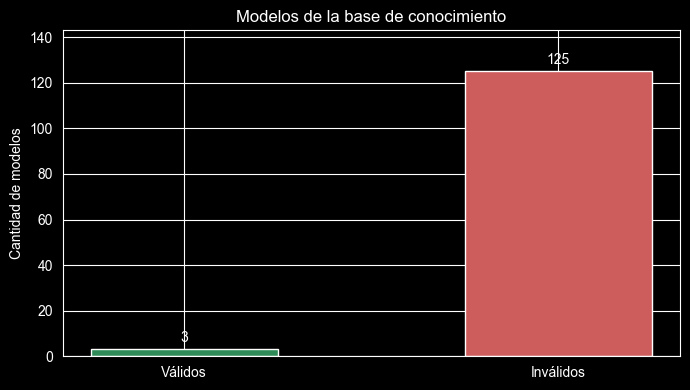

In [12]:

import matplotlib.pyplot as plt

categorias = ["Válidos", "Inválidos"]
cantidades = [total_validos, total_invalidos]

plt.figure(figsize=(7, 4))

barras = plt.bar(
    categorias,
    cantidades,
    color=["seagreen", "indianred"],
    width=0.5
)

plt.bar_label(barras, padding=3)

plt.title("Modelos de la base de conocimiento")
plt.ylabel("Cantidad de modelos")
plt.ylim(0, total_modelos + 15)

plt.tight_layout()
plt.show()



### 4.12. Visualización del mundo del Wumpus

Se representarán gráficamente las casillas analizadas por el agente.

La clasificación de cada casilla se realizará mediante TT-ENTAILS:

- Verde: ausencia de pozo demostrada.
- Rojo: presencia de pozo demostrada.
- Amarillo: presencia de pozo indeterminada.
- Gris: casilla no incluida en la base de conocimiento.

La clasificación se limita al peligro representado por los pozos.


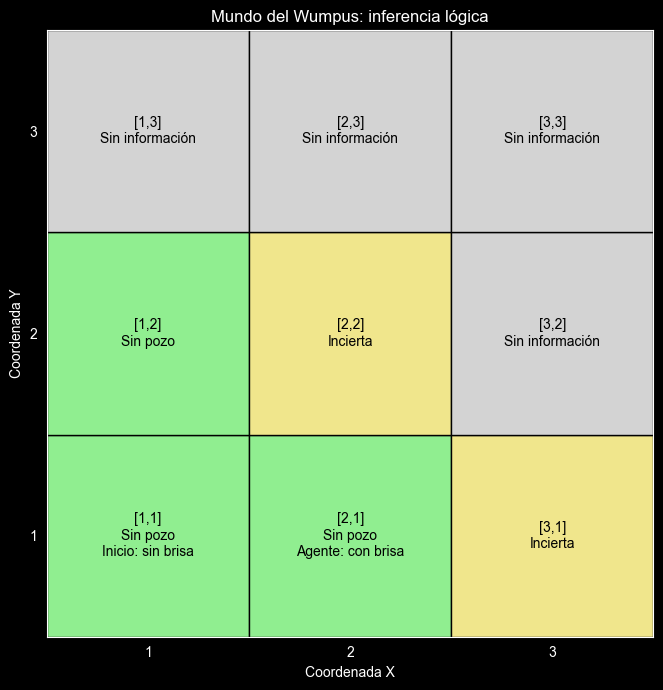

In [13]:

from matplotlib.patches import Rectangle

# Clasificar las casillas mediante inferencia lógica
def clasificar_casilla(simbolo):

    if simbolo not in SIMB:
        return "Sin información", "lightgray"

    if tt_entails(lambda m: not m[simbolo]):
        return "Sin pozo", "lightgreen"

    if tt_entails(lambda m: m[simbolo]):
        return "Con pozo", "lightcoral"

    return "Incierta", "khaki"


# Crear la figura
fig, ax = plt.subplots(figsize=(7, 7))

# Dibujar una cuadrícula de 3 x 3
for x in range(1, 4):
    for y in range(1, 4):

        simbolo = f"P{x}{y}"

        estado, color = clasificar_casilla(simbolo)

        casilla = Rectangle(
            (x - 1, y - 1),
            1, 1,
            facecolor=color,
            edgecolor="black"
        )

        ax.add_patch(casilla)

        texto = f"[{x},{y}]\n{estado}"

        if (x, y) == (1, 1):
            texto += "\nInicio: sin brisa"

        elif (x, y) == (2, 1):
            texto += "\nAgente: con brisa"

        ax.text(
            x - 0.5,
            y - 0.5,
            texto,
            ha="center",
            va="center",
            fontsize=10,
            color="black"
        )

# Configurar los ejes
ax.set_xlim(0, 3)
ax.set_ylim(0, 3)

ax.set_xticks([0.5, 1.5, 2.5])
ax.set_xticklabels([1, 2, 3])

ax.set_yticks([0.5, 1.5, 2.5])
ax.set_yticklabels([1, 2, 3])

ax.set_xlabel("Coordenada X")
ax.set_ylabel("Coordenada Y")

ax.set_aspect("equal")

ax.set_title("Mundo del Wumpus: inferencia lógica")

plt.tight_layout()
plt.show()



#### Interpretación de la visualización

El agente puede determinar mediante inferencia lógica que las casillas [1,1], [1,2] y [2,1] están libres de pozos.

Las casillas [2,2] y [3,1] presentan incertidumbre. Aunque se sabe que al menos una contiene un pozo, no es posible determinar individualmente cuál de ellas lo contiene.

Las casillas restantes no forman parte de la base de conocimiento, por lo que no se dispone de información suficiente para clasificarlas.



## 5. Conexión con la Unidad 1

### 5.1. Tabla REAS del agente del Wumpus

El modelo REAS permite describir las características de un agente inteligente mediante cuatro componentes: rendimiento, entorno, actuadores y sensores.

| Componente | Descripción |
|---|---|
| Rendimiento (R) | Identificar casillas libres de pozos, evitar peligros, tomar decisiones correctas y minimizar movimientos innecesarios. |
| Entorno (E) | Cueva representada mediante una cuadrícula de casillas que pueden contener pozos. |
| Actuadores (A) | Mecanismos que permiten avanzar, girar y desplazarse entre las casillas. |
| Sensores (S) | Mecanismos que permiten detectar la presencia o ausencia de brisa en la casilla actual. |

En esta práctica se implementa el componente de razonamiento lógico del agente. Los sensores se representan mediante proposiciones y los actuadores se describen conceptualmente, sin implementar físicamente los movimientos.



### 5.2. Clasificación del entorno

| Característica | Clasificación | Justificación |
|---|---|---|
| Observabilidad | Parcialmente observable | El agente únicamente percibe información local y desconoce el contenido de otras casillas. |
| Determinismo | Determinista | Las acciones y las condiciones del entorno tienen consecuencias determinadas. |
| Episodicidad | Secuencial | Las decisiones actuales dependen de las percepciones y acciones anteriores. |
| Dinamismo | Estático | La ubicación de los pozos no cambia mientras el agente razona. |
| Continuidad | Discreto | Las posiciones, acciones y percepciones tienen valores discretos. |
| Número de agentes | Monoagente | Existe un único agente inteligente encargado de explorar y razonar sobre el entorno. |



## 6. Cuestionario

### 1. Explica con tus palabras por qué ni P₂₂ ni ¬P₂₂ son consecuencia lógica de la KB.

Porque existen diferentes modelos que satisfacen todas las reglas de la base de conocimiento, pero no coinciden en el valor de verdad de P₂₂.

En el primer modelo válido, P₂₂ es falso, mientras que en los otros dos modelos es verdadero.

Para que una proposición sea consecuencia lógica de la KB debe ser verdadera en todos sus modelos válidos.

Por lo tanto:

$$KB \not\models P_{22}$$

$$KB \not\models \neg P_{22}$$

El agente no dispone de información suficiente para determinar si existe un pozo en la casilla [2,2].



### 2. ¿Cuántos modelos habría que revisar con 20 símbolos? ¿Qué implica para agentes reales?

El número de modelos posibles se calcula mediante:

$$N = 2^n$$

Para 20 símbolos proposicionales:

$$2^{20} = 1\,048\,576$$

En el peor caso, el algoritmo tendría que revisar 1,048,576 modelos.

Esto implica que la comprobación exhaustiva de modelos puede resultar poco eficiente para agentes reales que manejan grandes cantidades de información.

Cada símbolo adicional duplica el número de modelos posibles. Por ello, es conveniente utilizar métodos de inferencia más eficientes, como la resolución lógica.


In [14]:

# Cantidad de símbolos proposicionales
cant_simbolos = [5, 7, 10, 15, 20]

# Calcular los modelos posibles
cant_modelos = [2 ** n for n in cant_simbolos]

# Crear tabla
df_complejidad = pd.DataFrame({
    "Símbolos": cant_simbolos,
    "Modelos posibles": cant_modelos
})

df_complejidad


,Símbolos,Modelos posibles
0,5,32
1,7,128
2,10,1024
3,15,32768
4,20,1048576


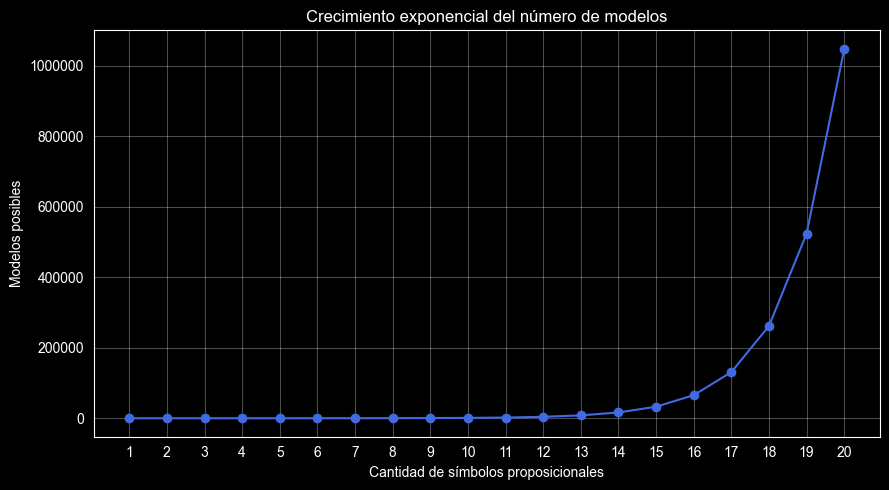

In [15]:

# Generar valores desde 1 hasta 20 símbolos
simbolos = list(range(1, 21))
cantidad = [2 ** n for n in simbolos]

plt.figure(figsize=(9, 5))

plt.plot(
    simbolos,
    cantidad,
    marker="o",
    color="royalblue"
)

plt.title("Crecimiento exponencial del número de modelos")
plt.xlabel("Cantidad de símbolos proposicionales")
plt.ylabel("Modelos posibles")
plt.xticks(range(1, 21))
plt.ticklabel_format(style="plain", axis="y")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### 3. ¿Qué tipo de agente (de la taxonomía de la Unidad 1) es este? Justifica.

Es un agente lógico basado en conocimiento que utiliza un modelo interno del entorno.

No se limita a reaccionar ante la percepción actual, sino que almacena hechos y reglas en una base de conocimiento y utiliza mecanismos de inferencia para obtener información nueva.

Por ejemplo, a partir de la ausencia de brisa en [1,1], puede deducir que las casillas vecinas están libres de pozos, aunque no las haya visitado.

Dentro de la taxonomía de agentes inteligentes, presenta las características de un agente basado en modelos, ya que utiliza una representación interna de un entorno parcialmente observable.



### 4. Si el agente se moviera a [1,2] y no percibiera brisa, ¿qué regla agregarías y qué podría concluir?

Se incorporaría una regla que relacione la brisa de [1,2] con la presencia de pozos en sus casillas vecinas.

**R6. Relación entre brisa y pozos vecinos:**

$$B_{12}\Leftrightarrow(P_{11}\lor P_{13}\lor P_{22})$$

**R7. Nueva percepción del agente:**

$$\neg B_{12}$$

A partir de estas reglas se puede deducir:

$$\neg P_{11}\land\neg P_{13}\land\neg P_{22}$$

Por otra parte, la base de conocimiento original establece:

$$P_{22}\lor P_{31}$$

Como ahora sabemos que P₂₂ es falso, podemos concluir que:

$$P_{31}$$

Por lo tanto:

- La casilla [2,2] está libre de pozos.
- La casilla [1,3] está libre de pozos.
- La casilla [3,1] contiene un pozo.

La nueva percepción permite resolver la incertidumbre que existía anteriormente.



## 7. Experimentación adicional

### 7.1. Ampliación de la base de conocimiento

Se agregarán dos símbolos proposicionales:

- P13: existe un pozo en [1,3].
- B12: existe brisa en [1,2].

La base de conocimiento ampliada conservará las cinco reglas originales e incorporará las reglas R6 y R7.

El número de modelos posibles aumentará de 128 a 512:

$$2^9 = 512$$


In [16]:

# Ampliar los símbolos sin modificar la lista original
SIMB_EXT = SIMB + ["P13", "B12"]


def KB_extendida(m):
    """Evalúa las reglas originales y las nuevas percepciones."""

    # R6: Brisa en [1,2] si y solo si hay un pozo vecino
    r6 = iff(
        m["B12"],
        m["P11"] or m["P13"] or m["P22"]
    )

    # R7: No hay brisa en [1,2]
    r7 = not m["B12"]

    return KB(m) and r6 and r7


def modelos_extendidos():
    """Genera los modelos de los nueve símbolos."""

    for vals in itertools.product(
        [False, True],
        repeat=len(SIMB_EXT)
    ):
        yield dict(zip(SIMB_EXT, vals))


# Filtrar los modelos válidos
mods_ext = [
    m for m in modelos_extendidos()
    if KB_extendida(m)
]

print("Símbolos:", len(SIMB_EXT))
print("Modelos posibles:", 2 ** len(SIMB_EXT))
print("Modelos válidos:", len(mods_ext))

pd.DataFrame(mods_ext)


Símbolos: 9
Modelos posibles: 512
Modelos válidos: 1


,P11,P12,P21,P22,P31,B11,B21,P13,B12
0,False,False,False,False,True,False,True,False,False



### 7.2. Consultas a la base de conocimiento ampliada

Se comprobará si las nuevas percepciones permiten determinar la presencia o ausencia de pozos en las casillas que anteriormente presentaban incertidumbre.


In [17]:

def tt_entails_extendido(alfa):
    """Comprueba consecuencias de la KB ampliada."""

    for m in modelos_extendidos():

        if KB_extendida(m) and not alfa(m):
            return False

    return True


consultas_ext = [
    ("¬P22", lambda m: not m["P22"]),
    ("¬P13", lambda m: not m["P13"]),
    ("P31", lambda m: m["P31"])
]

df_consultas_ext = pd.DataFrame([
    {
        "Consulta": nombre,
        "Resultado": tt_entails_extendido(alfa)
    }
    for nombre, alfa in consultas_ext
])

df_consultas_ext


,Consulta,Resultado
0,¬P22,True
1,¬P13,True
2,P31,True



### 7.3. Comparación antes y después de la nueva percepción

| Casilla | KB original | KB ampliada |
|---|---|---|
| [1,1] | Sin pozo | Sin pozo |
| [1,2] | Sin pozo | Sin pozo |
| [2,1] | Sin pozo | Sin pozo |
| [2,2] | Incierta | Sin pozo |
| [3,1] | Incierta | Con pozo |
| [1,3] | Sin información | Sin pozo |

La incorporación de una nueva percepción reduce la cantidad de modelos válidos de tres a uno.

Esto demuestra que agregar conocimiento puede reducir la incertidumbre del agente y mejorar su capacidad para tomar decisiones.


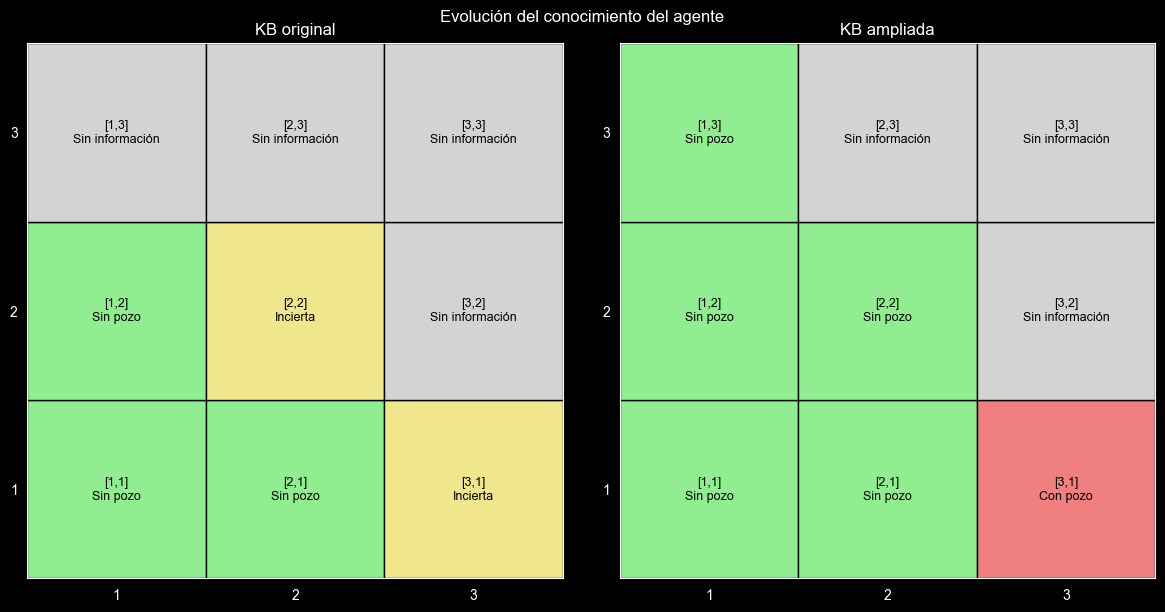

In [18]:

def dibujar_entorno(ax, simbolos, inferencia, titulo):

    for x in range(1, 4):
        for y in range(1, 4):

            simbolo = f"P{x}{y}"

            if simbolo not in simbolos:
                estado, color = "Sin información", "lightgray"

            elif inferencia(lambda m: not m[simbolo]):
                estado, color = "Sin pozo", "lightgreen"

            elif inferencia(lambda m: m[simbolo]):
                estado, color = "Con pozo", "lightcoral"

            else:
                estado, color = "Incierta", "khaki"

            ax.add_patch(Rectangle(
                (x - 1, y - 1),
                1, 1,
                facecolor=color,
                edgecolor="black"
            ))

            ax.text(
                x - 0.5,
                y - 0.5,
                f"[{x},{y}]\n{estado}",
                ha="center",
                va="center",
                fontsize=9,
                color="black"
            )

    ax.set_xlim(0, 3)
    ax.set_ylim(0, 3)

    ax.set_xticks([0.5, 1.5, 2.5], [1, 2, 3])
    ax.set_yticks([0.5, 1.5, 2.5], [1, 2, 3])

    ax.set_aspect("equal")
    ax.set_title(titulo)


fig, ejes = plt.subplots(1, 2, figsize=(12, 6))

dibujar_entorno(
    ejes[0],
    SIMB,
    tt_entails,
    "KB original"
)

dibujar_entorno(
    ejes[1],
    SIMB_EXT,
    tt_entails_extendido,
    "KB ampliada"
)

plt.suptitle("Evolución del conocimiento del agente")

plt.tight_layout()
plt.show()



## 8. Conclusiones

Mediante esta práctica se comprendió cómo la lógica proposicional permite representar el conocimiento de un agente inteligente y obtener conclusiones a partir de hechos y reglas.

Se implementó el algoritmo TT-ENTAILS para comprobar consecuencias lógicas mediante la enumeración de modelos. De los 128 modelos posibles, únicamente tres satisficieron la base de conocimiento original.

Los resultados permitieron identificar casillas libres de pozos y reconocer situaciones en las que la información disponible no era suficiente para establecer una conclusión definitiva.

También se identificó la importancia del bicondicional para representar correctamente la relación entre las percepciones de brisa y la presencia de pozos vecinos.

Mediante la ampliación de la base de conocimiento se comprobó que incorporar nuevas percepciones permite reducir la incertidumbre. En este caso, se pasó de tres modelos válidos a uno, lo que permitió determinar la ubicación de un pozo.

Finalmente, se reconoció que la comprobación exhaustiva de modelos tiene una complejidad exponencial, lo que motiva el estudio de métodos de inferencia más eficientes para problemas de mayor tamaño.



## 9. Referencias

Campero Domínguez, J. I. (s. f.). *Inteligencia artificial (CDC-2411): Manual de prácticas, Unidad 3. Representación del conocimiento y razonamiento*. Tecnológico Nacional de México.

## 10. Declaración de uso de inteligencia artificial

Se utilizó ChatGPT, de OpenAI, como herramienta de apoyo para comprender los conceptos de lógica proposicional, estructurar el Notebook, desarrollar y explicar el código Python, analizar los resultados y generar visualizaciones complementarias.
